# Statistical analysis of four dimuon resonances in CMS Open Data: $J/\psi$, $\psi(2S)$, $\Upsilon(1S)$ and $Z$

**Student Name:** Aditya Kumar Choubey  
**Course:** Statistical Inference for High Energy Physics  
**Affiliation:** Indian Institute of Science Education and Research (IISER) Pune  
**Dataset:** CMS Open Data, 2016 DoubleMuon Run G, NanoAOD, $\sqrt{s} = 13$ TeV

---

## 1. Objective

If we use only a loose muon selection, the dimuon mass spectrum shows many resonances at the same time, spread over a large range of mass. In this notebook I apply the same set of statistical tests to four of them.

| particle | PDG mass [GeV] | natural width | what decides the peak shape |
|---|---|---|---|
| $J/\psi$ | 3.0969 | 93 keV | detector resolution + radiation tail (Crystal Ball) |
| $\psi(2S)$ | 3.6861 | 294 keV | detector resolution (shape tied to $J/\psi$) |
| $\Upsilon(1S)$ | 9.4603 | 54 keV | detector resolution + radiation tail (tied to $\Upsilon(2S)$, $\Upsilon(3S)$) |
| $Z$ | 91.1876 | 2.4952 GeV | Breit-Wigner $\otimes$ Crystal Ball (convolution done numerically) |


What I do in this notebook:
1. One fit to all the muon pairs in each mass window (Section 4). The barrel/endcap resolution difference is only shown in Section 2.1, I do not use it in the fit.
2. Signal shape: Crystal Ball / double Crystal Ball for the narrow resonances, Breit-Wigner convolution for the $Z$.
3. Extended unbinned likelihood fit with `iminuit` (yield, mass, resolution, and also the width for the $Z$).
4. Discovery test, $H_0: N = 0$, using the likelihood ratio $q_0$.
5. Mass test, $H_0: m = m_{\text{PDG}}$, and a profile-likelihood scan of the mass for each particle.
6. $\Upsilon$ mass splittings $\Delta m_{21}$, $\Delta m_{31}$, which are mostly not affected by a common momentum-scale error.
7. $Z$ width test, $H_0: \Gamma = 2.4952$ GeV.
8. Likelihood contours and a 3D surface in the (mass, resolution) plane.
9. Binned fit as a cross-check, with a goodness-of-fit test.

In [1]:
# pip install iminuit uproot awkward aiohttp fsspec
import os, time, hashlib
import numpy as np
import scipy.stats as stats
from scipy.signal import fftconvolve
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D   # noqa: needed for the 3D plot on older matplotlib
from iminuit import Minuit
import uproot
import awkward as ak

plt.rcParams.update({'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 13, 'figure.dpi': 120})

# settings (make GRID_N smaller for a quick run)
GRID_N      = 9       # GRID_N x GRID_N fits per region
MASS_WINDOW = 0.015   # masses may move +-1.5 % around PDG

# model settings
ETA_EDGE   = 1.2      # |eta| cut between barrel and endcap (only used for the plot in Section 2.1)
USE_GCORE  = True     # add a narrow Gaussian on top of the CB/DCB (peak is sharper than one CB); region B turns it off (few events)
USE_DCB    = True     # CB with tails on both sides (False = normal one-sided CB), Z region always uses False
DCB_NL     = 3.0      # fixed power of the low-mass tail
DCB_NR     = 3.0      # fixed power of the high-mass tail

PRETTY = {'J/psi': r'$J/\psi$', 'psi(2S)': r'$\psi(2S)$', 'Y(1S)': r'$\Upsilon(1S)$',
          'Y(2S)': r'$\Upsilon(2S)$', 'Y(3S)': r'$\Upsilon(3S)$', 'Z': r'$Z$'}

---
## 2. Data and event selection

* two opposite-charge muons (the two highest-$p_T$ muons in the event)
* $p_T > 3$ GeV for both
* $|\eta| < 2.4$
* no muon ID and no isolation, because they remove too many of the low-mass pairs


In [2]:
# input files, add more if stats are too low
FILES = [
    'http://opendata.cern.ch/eos/opendata/cms/Run2016G/DoubleMuon/NANOAOD/UL2016_MiniAODv2_NanoAODv9-v2/2430000/4E3A26DE-E53B-A844-8048-36376617AE8D.root',
]
branches = ['nMuon', 'Muon_pt', 'Muon_eta', 'Muon_phi', 'Muon_mass', 'Muon_charge']
CACHE = 'dimuon_v3_' + hashlib.md5(''.join(FILES).encode()).hexdigest()[:8] + '.npy'   # columns: m_mumu, |eta1|, |eta2|

def dimuon_from_file(url):
    with uproot.open(url) as f:
        ev = f['Events'].arrays(branches)
    n_events = len(ev)
    ev = ev[ev.nMuon >= 2]
    p1, p2 = ev.Muon_pt[:, 0], ev.Muon_pt[:, 1]
    eta1, eta2 = ev.Muon_eta[:, 0], ev.Muon_eta[:, 1]
    phi1, phi2 = ev.Muon_phi[:, 0], ev.Muon_phi[:, 1]
    mm1, mm2 = ev.Muon_mass[:, 0], ev.Muon_mass[:, 1]
    cut = ((ev.Muon_charge[:, 0] != ev.Muon_charge[:, 1]) &
           (p1 > 3.0) & (p2 > 3.0) & (np.abs(eta1) < 2.4) & (np.abs(eta2) < 2.4))
    px1, py1, pz1 = p1*np.cos(phi1), p1*np.sin(phi1), p1*np.sinh(eta1)
    px2, py2, pz2 = p2*np.cos(phi2), p2*np.sin(phi2), p2*np.sinh(eta2)
    E1 = np.sqrt(px1**2 + py1**2 + pz1**2 + mm1**2)
    E2 = np.sqrt(px2**2 + py2**2 + pz2**2 + mm2**2)
    m2_ = (E1+E2)**2 - (px1+px2)**2 - (py1+py2)**2 - (pz1+pz2)**2
    keep = lambda x: np.asarray(x[cut], dtype=np.float64)
    out = np.column_stack([keep(np.sqrt(np.maximum(m2_, 0))), keep(np.abs(eta1)), keep(np.abs(eta2))])
    return out, n_events

if os.path.exists(CACHE):
    arr = np.load(CACHE)
    print(f"Loaded {len(arr)} dimuon pairs from the cache file {CACHE}")
else:
    print("Streaming data from CERN Open Data...")
    t0 = time.time()
    chunks, n_ev_total = [], 0
    for u in FILES:
        a_f, n_ev = dimuon_from_file(u)
        chunks.append(a_f); n_ev_total += n_ev
    arr = np.concatenate(chunks)
    arr = arr[np.isfinite(arr).all(axis=1) & (arr[:, 0] > 1.0) & (arr[:, 0] < 200.0)]
    np.save(CACHE, arr)
    print(f"Done in {time.time()-t0:.1f} s. {n_ev_total} events read, {len(arr)} dimuon pairs pass the loose selection.")

m_all, aeta1_all, aeta2_all = arr[:, 0], arr[:, 1], arr[:, 2]

Streaming data from CERN Open Data...
Done in 4.5 s. 65826 events read, 32403 dimuon pairs pass the loose selection.


### 2.1 Detector geometry

The CMS momentum resolution $\sigma(p_T)/p_T$ is worse in the endcap ($|\eta| \ge 1.2$) than in the barrel ($|\eta| < 1.2$). The lever arm is shorter and there is more material, so there is more multiple scattering and bremsstrahlung.

I checked this by splitting pairs into BB, BE and EE and comparing the peak widths (half of the central 68 % interval) in the $J/\psi$ and $Z$ windows. The endcap pairs are clearly wider. This is only a rough check, since the width still includes the background under the peak.

All pairs are fitted together, so the fitted $\sigma$ is an average over BB, BE and EE. This mixture of resolutions is one reason the peak is non-Gaussian and needs tail parameters (Section 3).

$J/\psi$ region          half-68% width: BB = 36.5 MeV,  BE = 52.3 MeV,  EE = 62.8 MeV   (relative to BB: 1.00, 1.43, 1.72)
$Z$ region               half-68% width: BB = 3.1 GeV,  BE = 3.7 GeV,  EE = 4.0 GeV   (relative to BB: 1.00, 1.18, 1.28)


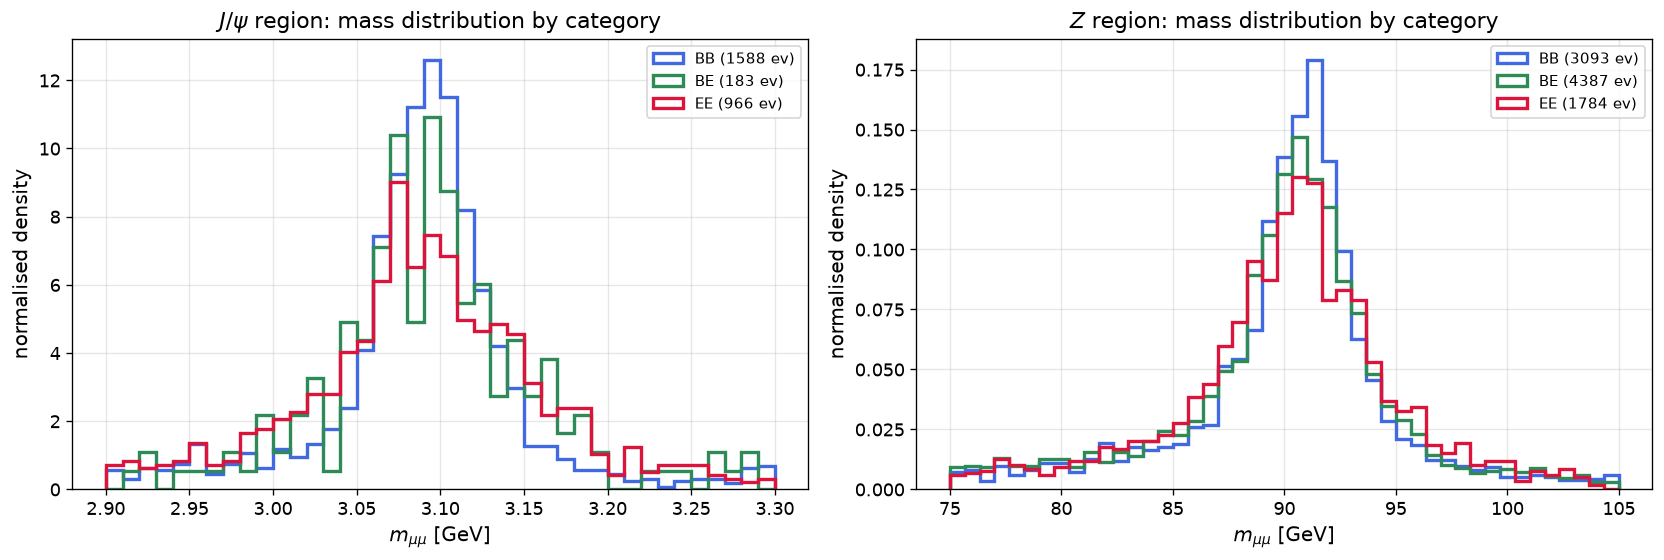

In [3]:
# compare BB / BE / EE (only to illustrate, this is not used in the fits)
b1, b2 = aeta1_all < ETA_EDGE, aeta2_all < ETA_EDGE
cat3 = np.where(b1 & b2, 0, np.where(b1 | b2, 1, 2))
names3 = ['BB', 'BE', 'EE']
cols3 = ['royalblue', 'seagreen', 'crimson']
wins = [(r'$J/\psi$ region', 2.9, 3.3, 40, 1000.0, 'MeV'), (r'$Z$ region', 75.0, 105.0, 45, 1.0, 'GeV')]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, (title, lo, hi, nb, scale, unit) in zip(axes, wins):
    sel = (m_all >= lo) & (m_all <= hi)
    widths = []
    for c, (nm, col) in enumerate(zip(names3, cols3)):
        x = m_all[sel & (cat3 == c)]
        widths.append(0.5*(np.percentile(x, 84) - np.percentile(x, 16)))
        ax.hist(x, bins=nb, range=(lo, hi), density=True, histtype='step', lw=2, color=col, label=f'{nm} ({len(x)} ev)')
    ax.set_title(title + ': mass distribution by category')
    ax.set_xlabel(r'$m_{\mu\mu}$ [GeV]'); ax.set_ylabel('normalised density'); ax.legend(fontsize=9); ax.grid(alpha=0.3)
    print(f"{title:<24} half-68% width: " + ",  ".join(f"{nm} = {scale*w:.1f} {unit}" for nm, w in zip(names3, widths))
          + "   (relative to BB: " + ", ".join(f"{w/widths[0]:.2f}" for w in widths) + ")")
plt.tight_layout(); plt.show()


# 3. The Model

We divide the dimuon invariant-mass spectrum into three separate mass regions. In each region, the observed distribution is described as a combination of signal peaks and a smooth background.

| Region | Mass window (GeV) | Signal resonances |
|:---:|:---:|:---|
| A | 2.7–4.1 | $J/\psi,\ \psi(2S)$ |
| B | 8.6–11.4 | $\Upsilon(1S),\ \Upsilon(2S),\ \Upsilon(3S)$ |
| C | 70–110 | $Z$ |

Each region is fitted independently. This means that each region has its own signal parameters, background parameters and event yields.

## 3.1 Signal Line Shape: Why Not a Gaussian?

In an ideal case, a resonance would produce a peak centred at its true mass. However, the experimentally measured mass is affected by detector resolution and other effects.

These effects can make the observed peak different from a simple Gaussian.

The main reasons are:

1. **Final-state radiation (FSR):** A muon can emit a photon while travelling through the detector. If this photon is not included in the reconstructed muon pair, the measured invariant mass becomes smaller than the actual value. This produces a tail on the low-mass side.

2. **Material effects:** Energy loss and bremsstrahlung in the tracker material can also contribute to the low-mass tail.

3. **Track mismeasurement:** Incorrectly measured tracks can produce events away from the central peak, including on the high-mass side.

Because of these effects, we use the **Crystal Ball (CB) function** instead of a simple Gaussian. It has a Gaussian central part and a power-law tail.

## 3.2 Crystal Ball Function

We define a dimensionless variable

$$
t=\frac{x}{\sigma},
\qquad x=m-m_0,
$$

where $m_0$ is the peak position and $\sigma$ is the width of the Gaussian core.

The single-sided Crystal Ball function is

$$
\mathrm{CB}(t)\propto
\begin{cases}
A(B-t)^{-n}, & t<-\alpha,\\[4pt]
\exp(-t^2/2), & t\geq-\alpha.
\end{cases}
$$

The constants are

$$
A=\left(\frac{n}{\alpha}\right)^n
\exp\left(-\frac{\alpha^2}{2}\right),
$$

$$
B=\frac{n}{\alpha}-\alpha.
$$

The parameters control different parts of the peak:

- $\sigma$ determines the width of the central Gaussian part.
- $\alpha$ determines where the power-law tail starts.
- $n$ controls how quickly the tail decreases.

In our fit, the tail exponent is fixed to

$$
n_L=3,
$$

while $\alpha_L$ (implemented as `alpha`) is allowed to vary.

## 3.3 Double Crystal Ball Function

A single Crystal Ball function describes only the low-mass tail. To allow a tail on both sides of the peak, we also use the Double Crystal Ball (DCB) function.

It is defined as

$$
\mathrm{DCB}(t)\propto
\begin{cases}
A_L(B_L-t)^{-n_L}, & t<-\alpha_L,\\[4pt]
\exp(-t^2/2), & -\alpha_L\leq t\leq\alpha_R,\\[4pt]
A_R(B_R+t)^{-n_R}, & t>\alpha_R.
\end{cases}
$$

The corresponding constants are

$$
A_i=
\left(\frac{n_i}{\alpha_i}\right)^{n_i}
\exp\left(-\frac{\alpha_i^2}{2}\right),
$$

$$
B_i=\frac{n_i}{\alpha_i}-\alpha_i.
$$

We fix both tail exponents:

$$
n_L=n_R=3.
$$

The two transition parameters, $\alpha_L$ and $\alpha_R$, are allowed to vary during the fit.

**In our implementation:**

- Region A uses the double-sided Crystal Ball.
- Region B also uses the double-sided Crystal Ball.
- Region C uses the single-sided Crystal Ball.

The choice can be controlled using `USE_DCB`. For the $Z$ region, the right-side tail is disabled separately.

## 3.4 Adding a Narrow Gaussian Core

While fitting the peaks, we found that a single Crystal Ball function was not always sufficient to describe the central part of the distribution.


To describe the sharper central part of the peak, we add a second Gaussian component with a smaller width.

The complete resolution function is

$$
\boxed{
R(x)=(1-f_g)\,\mathcal{C}(x;\sigma)
+f_g\,G(x;r_g\sigma)
}
$$

where $\mathcal{C}$ represents the Crystal Ball or Double Crystal Ball function, depending on the region.

The narrow Gaussian is

$$
G(x;r_g\sigma)=
\frac{1}{\sqrt{2\pi}\,r_g\sigma}
\exp\left[
-\frac{x^2}{2(r_g\sigma)^2}
\right].
$$

The new parameters are:

- $f_g$: Fraction of events described by the narrow Gaussian.
- $r_g$: Factor that determines the width of the narrow Gaussian.
- $\sigma$: Width of the broader Crystal Ball component.

We impose

$$
0<r_g<1.
$$

Therefore, the narrow Gaussian has a smaller width than the Crystal Ball component.

**We use this additional Gaussian component as follows:**

- Region A: Double Crystal Ball + narrow Gaussian.
- Region B: Double Crystal Ball only.
- Region C: Single Crystal Ball + narrow Gaussian.

Region B does not include the additional Gaussian because of its more limited statistics.

The parameters $f_g$ and $r_g$ are shared between all peaks within the same region.

## 3.5 Natural Width versus Detector Resolution

A resonance has an intrinsic physical width, called its natural width. This is different from the width introduced by the detector.

For example:

| Resonance | Natural width |
|:---|---:|
| $J/\psi$ | 93 keV |
| $\psi(2S)$ | 294 keV |
| $\Upsilon(1S)$ | 54 keV |

These widths are much smaller than the detector resolution:

- Approximately 40–50 MeV around 3 GeV.
- Approximately 100 MeV around 9.5 GeV.

Therefore, for the $J/\psi$, $\psi(2S)$ and $\Upsilon$ resonances, the natural widths are negligible compared with the detector resolution.

We can directly use the resolution function to describe their observed signal shapes:

$$
\boxed{
P_k(m)=R(m-m_k)
}
$$

where $m_k$ is the fitted mass of the corresponding resonance.

The $Z$ boson is different because its natural width is approximately 2.5 GeV. This is large enough that it must be included in the signal model.

## 3.6 Signal Model for the $Z$ Boson

For the $Z$ boson, we need to consider both its natural width and the detector resolution.

We do this by convolving a Breit-Wigner distribution with the resolution function.

The resulting signal PDF is

$$
\boxed{
P_Z(m)=
\frac{[\mathrm{BW}\otimes R](m)}
{\displaystyle\int_{m_{\min}}^{m_{\max}}
[\mathrm{BW}\otimes R](m')\,dm'}
}
$$

The convolution is defined as

$$
[\mathrm{BW}\otimes R](m)
=
\int_{-\infty}^{\infty}
\mathrm{BW}(m';m_Z,\Gamma)
R(m-m')\,dm'.
$$

In simple terms, the Breit-Wigner describes the natural shape of the resonance, while the resolution function describes the effect of the detector. Their convolution gives the shape that we expect to observe experimentally.



### 3.6.2 Resolution Function for the $Z$

For the $Z$ signal, we use a single-sided Crystal Ball function together with the narrow Gaussian component:

$$
\boxed{
R(x)=
(1-f_g)\,\mathrm{CB}(x;\sigma,\alpha_L)
+
f_g\,G(x;r_g\sigma)
}
$$

with

$$
n_L=3.
$$


Therefore, we use the single-sided Crystal Ball function for the $Z$ fit.

The double-sided version was tried but somehow did not converge while using MIGRAD for this region so i decided to use single sided CB*

### 3.6.3 Numerical Convolution

The convolution of a Breit-Wigner distribution with a Gaussian has an analytical solution called the Voigt profile.

However, our resolution function contains a Crystal Ball component, so we perform the convolution numerically.

We use the convolution theorem:

$$
\mathcal{F}\{f*g\}
=
\mathcal{F}\{f\}\mathcal{F}\{g\}.
$$

Therefore,

$$
\mathrm{BW}\otimes R
=
\mathcal{F}^{-1}
\left[
\mathcal{F}\{\mathrm{BW}\}
\mathcal{F}\{R\}
\right].
$$

The numerical procedure is:

1. Sample the Breit-Wigner and resolution functions on a fine mass grid.
2. Calculate their Fourier transforms.
3. Multiply the two transforms.
4. Apply the inverse Fourier transform to obtain the convolution.

We use `scipy.signal.fftconvolve` to perform this calculation.

The computational grid is extended by 30% of the original grid size on both sides of the fit window. This helps reduce boundary effects caused by the long Breit-Wigner tails.

Finally, the convolved distribution is normalised numerically inside the fit window.

### 3.6.4 Free Parameters of the $Z$ Signal

The $Z$ signal model has seven free parameters:

| Parameter | Description |
|:---|:---|
| $N_Z$ | Signal yield |
| $m_Z$ | Fitted resonance mass |
| $\sigma$ | Reference detector resolution |
| $\alpha_L$ | Low-mass tail parameter |
| $f_g$ | Narrow Gaussian fraction |
| $r_g$ | Narrow Gaussian width factor |
| $\Gamma$ | Natural width |

The background has its own additional parameters, which are discussed later.

An important point is that both $\sigma$ and $\Gamma$ affect the width of the observed peak.

This means that they can be strongly correlated. The fit tries to distinguish them using the different shapes of the detector-resolution tails and the Breit-Wigner distribution.


## 3.7 Background Model

The background is described using an exponential function:

$$
B(m)\propto e^{-\lambda(m-m_{\min})}.
$$

Here, $\lambda$ controls the slope of the background distribution.

We normalise the background PDF inside the fit window:

$$
\boxed{
B(m)=
\frac{e^{-\lambda(m-m_{\min})}}
{\displaystyle\int_{m_{\min}}^{m_{\max}}
e^{-\lambda(m'-m_{\min})}\,dm'}
}
$$

This ensures that

$$
\int_{m_{\min}}^{m_{\max}}B(m)\,dm=1.
$$

The background yield $N_B$ is fitted independently in each mass region.

## 3.8 Extended Maximum-Likelihood Fit

After defining the signal and background shapes, we combine them to construct the total probability density used in the fit.

For a given mass region, the total event intensity is

$$
\boxed{
\mathcal{I}(m)=
\sum_k N_kP_k(m)+N_BB(m)
}
$$

where:

- $N_k$ is the expected yield of the $k$-th resonance.
- $P_k(m)$ is the corresponding normalised signal PDF.
- $N_B$ is the expected background yield.
- $B(m)$ is the normalised background PDF.

All signal and background PDFs are normalised inside their respective fit windows.

We use an extended unbinned maximum-likelihood fit. The negative log-likelihood is

$$
\boxed{
-\ln L=
\left(\sum_kN_k+N_B\right)
-
\sum_{i=1}^{N}
\ln\left[
\sum_kN_kP_k(m_i)+N_BB(m_i)
\right]
}
$$

Here, $N$ is the number of observed dimuon pairs and $m_i$ is the invariant mass of the $i$-th pair.

The first term accounts for the total number of expected events, while the second term uses the measured mass of every individual event.

We minimise this negative log-likelihood using `iminuit` to obtain the best-fit signal yields, resonance masses, resolution parameters, natural width and background parameters.


In [4]:
# line shapes and the Region class (data, model, fit)
GAMMA_Z_PDG = 2.4952

def dcb(x, sigma, alphaL, alphaR=None, nL=DCB_NL, nR=DCB_NR):
    # double-sided Crystal Ball centred at 0, not normalised. alphaR=None gives the single CB
    t = x / sigma
    AL = (nL/alphaL)**nL * np.exp(-alphaL**2/2)
    BL = nL/alphaL - alphaL
    out = np.exp(-0.5*t**2)
    lo = t < -alphaL
    out[lo] = AL * (BL - t[lo])**(-nL)
    if alphaR is not None:
        AR = (nR/alphaR)**nR * np.exp(-alphaR**2/2)
        BR = nR/alphaR - alphaR
        hi = t > alphaR
        out[hi] = AR * (BR + t[hi])**(-nR)
    return out

def crystal_ball(x, sigma, alpha):
    return dcb(x, sigma, alpha, None)

class Region:
    NSUB = 40      # fine grid points per histogram bin

    def __init__(self, name, lo, hi, nbins, peaks, masses, sig_guess,
                 use_bw=False, mass_window=MASS_WINDOW, dcb=None, gcore=None):
        self.name, self.lo, self.hi, self.nbins = name, lo, hi, nbins
        self.peaks, self.M = peaks, np.array(masses, dtype=float)
        self.K = len(peaks)
        self.sig_guess = sig_guess
        self.use_bw = use_bw                          # Breit-Wigner x resolution (only for the Z)
        self.dcb = USE_DCB if dcb is None else dcb    # tail on the right side on/off
        self.gcore = USE_GCORE if gcore is None else gcore   # narrow Gaussian core on top of the CB/DCB
        self.mw = mass_window
        sel = (m_all >= lo) & (m_all <= hi)
        self.data = m_all[sel]
        self.N = len(self.data)
        # fine grid used for the pdfs: nbins * NSUB cells
        self.ng = nbins*self.NSUB
        self.dx = (hi - lo)/self.ng
        self.xe = lo + self.dx*np.arange(self.ng + 1)
        self.xg = 0.5*(self.xe[:-1] + self.xe[1:])
        self.npad = int(0.3*self.ng)
        self.ext = lo - self.npad*self.dx + self.dx*(np.arange(self.ng + 2*self.npad) + 0.5)
        self.kx = self.dx*np.arange(-self.npad, self.npad + 1)
        # histogram of the data
        self.counts, self.bin_edges = np.histogram(self.data, bins=nbins, range=(lo, hi))
        self.bin_centers = 0.5*(self.bin_edges[:-1] + self.bin_edges[1:])
        self.bin_width = self.bin_edges[1] - self.bin_edges[0]
        # parameter names
        self.names = ([f'n{k}' for k in range(self.K)] + ['nb'] +
                      [f'm{k}' for k in range(self.K)] + ['sig', 'alpha'] +
                      (['alphaR'] if self.dcb else []) + (['fg', 'rg'] if self.gcore else []) + ['lam'] +
                      (['gam'] if use_bw else []))
        # parameters that describe the signal shape (kept fixed in the null fit when the region has only one peak)
        self.signal_shape_names = [n for n in self.names if n in ('sig', 'alpha', 'alphaR', 'gam', 'fg', 'rg')]
        self.ndof = nbins - len(self.names)
        self._make_start()

    def _make_start(self):
        med = np.median(self.counts)/self.bin_width        # background per GeV
        st = {}
        n_sig = 0.0
        for k in range(self.K):
            sg = self.sig_guess*self.M[k]/self.M[0]
            c = np.sum(np.abs(self.data - self.M[k]) < 2.5*sg)
            st[f'n{k}'] = max(c - med*5*sg, 10.0)
            st[f'm{k}'] = self.M[k]
            n_sig += st[f'n{k}']
        st.update(nb=max(self.N - n_sig, 0.1*self.N), sig=self.sig_guess, alpha=1.5, lam=0.0)
        if self.dcb:
            st['alphaR'] = 2.0
        if self.gcore:
            st['fg'], st['rg'] = 0.3, 0.5
        if self.use_bw:
            st['gam'] = GAMMA_Z_PDG
        self.start = st

    # shapes on the fine grid
    @staticmethod
    def resolution(x, sig, alpha, alphaR=None, fg=None, rg=None):
        # resolution function that sums to 1: (1 - fg) * (D)CB of width sig + fg * narrow Gaussian of width rg*sig
        f = dcb(x, sig, alpha, alphaR); f = f/f.sum()
        if fg is None:
            return f
        g = np.exp(-0.5*(x/(rg*sig))**2); g = g/g.sum()
        return (1 - fg)*f + fg*g

    def peak_shape(self, mass, sig, alpha, gam=None, alphaR=None, fg=None, rg=None):
        if self.use_bw:
            h = gam/2.0
            bw = h/((self.ext - mass)**2 + h**2)
            ker = self.resolution(self.kx, sig, alpha, alphaR, fg, rg)
            f = fftconvolve(bw, ker, mode='same')[self.npad:self.npad + self.ng]
        else:
            f = self.resolution(self.xg - mass, sig, alpha, alphaR, fg, rg)
        return f/(f.sum()*self.dx)

    def bkg_shape(self, p):
        # exponential background, normalised in the window
        f = np.exp(-p['lam']*(self.xg - self.lo))
        return f/(f.sum()*self.dx)

    def components(self, p):
        # (yield, pdf on the grid) for every peak, then the background
        out = []
        for k in range(self.K):
            sk = p['sig']*self.M[k]/self.M[0]          # resolution scales with the mass
            pdf = self.peak_shape(p[f'm{k}'], sk, p['alpha'], p.get('gam'), p.get('alphaR'), p.get('fg'), p.get('rg'))
            out.append((p[f'n{k}'], pdf))
        out.append((p['nb'], self.bkg_shape(p)))
        return out

    def density_grid(self, p):
        return sum(y*pdf for y, pdf in self.components(p))

    def expected_bins(self, p):
        return (self.density_grid(p)*self.dx).reshape(self.nbins, self.NSUB).sum(axis=1)

    def deviance(self, p):
        # Poisson deviance of the histogram
        mu, n = self.expected_bins(p), self.counts
        nz = n > 0
        return 2*np.sum(mu - n) + 2*np.sum(n[nz]*np.log(n[nz]/mu[nz]))

    # fitting
    def fit(self, fix=None, start=None, binned=False, minos=(), tie=None):
        # tie=(k, r, delta) forces m_k = m_r + delta, used for the splitting scan
        names = self.names
        def fcn(par):
            p = dict(zip(names, par))
            if tie is not None:
                p[f'm{tie[0]}'] = p[f'm{tie[1]}'] + tie[2]
            if p['sig'] < 1e-4 or p['alpha'] < 0.1 or p.get('alphaR', 1.0) < 0.1:
                return 1e12
            dens = self.density_grid(p)
            if binned:
                mu = (dens*self.dx).reshape(self.nbins, self.NSUB).sum(axis=1)
                if np.any(mu <= 0):
                    return 1e12
                return np.sum(mu - self.counts*np.log(mu))
            ntot = sum(p[f'n{k}'] for k in range(self.K)) + p['nb']
            d = np.interp(self.data, self.xg, dens)
            if np.any(d <= 0):
                return 1e12
            return ntot - np.sum(np.log(d))
        st = dict(self.start)
        if start:
            st.update({k: v for k, v in start.items() if k in st})
        if fix:
            st.update(fix)
        m = Minuit(fcn, np.array([st[k] for k in names]), name=names)
        N = self.N
        L = 12.0/(self.hi - self.lo)
        for k in range(self.K):
            m.limits[f'n{k}'] = (0, 3*N)
            m.limits[f'm{k}'] = (self.M[k]*(1 - self.mw), self.M[k]*(1 + self.mw))
        m.limits['nb'] = (0, 3*N)
        m.limits['sig'] = (0.25*self.sig_guess, 4*self.sig_guess)
        m.limits['alpha'] = (0.3, 5.0)
        if self.dcb:
            m.limits['alphaR'] = (0.3, 5.0)
        if self.gcore:
            m.limits['fg'] = (1e-3, 0.9)
            m.limits['rg'] = (0.2, 0.95)
        m.limits['lam'] = (-L, L)
        if self.use_bw:
            m.limits['gam'] = (0.8, 6.0)
        m.errordef = Minuit.LIKELIHOOD
        if fix:
            for k in fix:
                m.fixed[k] = True
        if tie is not None:
            m.fixed[f'm{tie[0]}'] = True
        m.migrad()
        if not m.valid:
            m.migrad()
        m.hesse()
        for k in minos:
            try:
                m.minos(k)
            except Exception:
                pass
        return dict(values=m.values.to_dict(), errors=m.errors.to_dict(), fval=m.fval, valid=m.valid, m=m)

regions = {
    'A': Region('A: J/psi, psi(2S)', 2.7, 4.1, 60, ['J/psi', 'psi(2S)'], [3.0969, 3.6861], sig_guess=0.045),
    'B': Region('B: Upsilon family', 8.6, 11.4, 60, ['Y(1S)', 'Y(2S)', 'Y(3S)'], [9.4603, 10.0233, 10.3552], sig_guess=0.12, gcore=False),
    'C': Region('C: Z', 70.0, 110.0, 60, ['Z'], [91.1876], sig_guess=2.0, use_bw=True, dcb=False),
}
# the four main particles: (region key, index of the peak in that region)
MAIN = [('A', 0), ('A', 1), ('B', 0), ('C', 0)]

for key, R in regions.items():
    print(f"region {R.name:<22} window [{R.lo}, {R.hi}] GeV: {R.N} events, {len(R.names)} parameters")


region A: J/psi, psi(2S)      window [2.7, 4.1] GeV: 3623 events, 11 parameters
region B: Upsilon family      window [8.6, 11.4] GeV: 1251 events, 11 parameters
region C: Z                   window [70.0, 110.0] GeV: 9810 events, 9 parameters


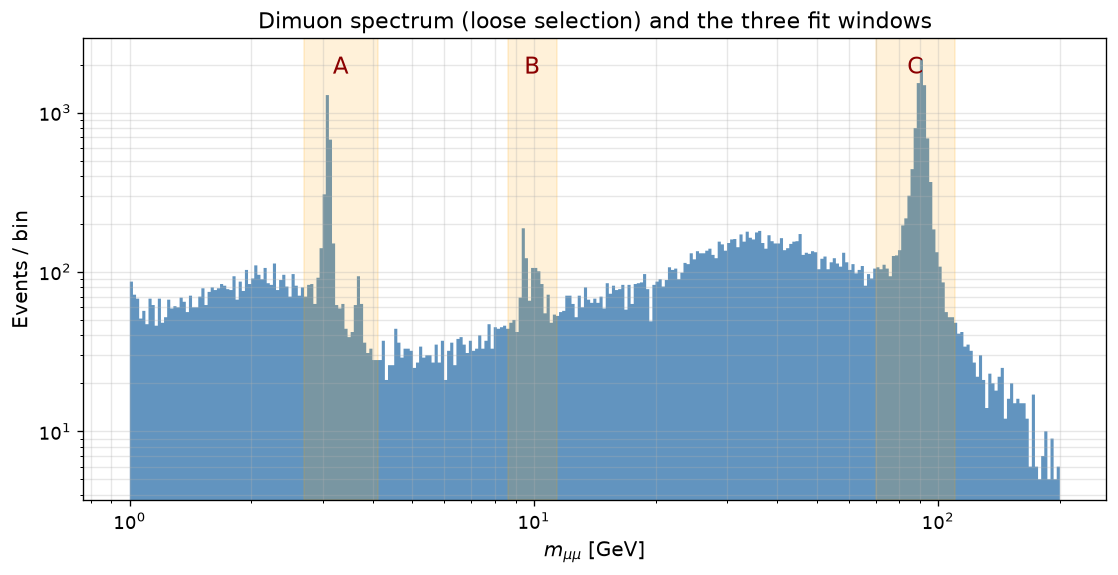

In [5]:
# the full spectrum with the three fit windows
fig, ax = plt.subplots(figsize=(11, 5))
bins_log = np.logspace(0, np.log10(200), 300)
ax.hist(m_all, bins=bins_log, color='steelblue', histtype='stepfilled', alpha=0.85)
ax.set_xscale('log'); ax.set_yscale('log')
for key, R in regions.items():
    ax.axvspan(R.lo, R.hi, alpha=0.15, color='orange')
    ax.text(np.sqrt(R.lo*R.hi), ax.get_ylim()[1]*0.6, key, ha='center', fontsize=14, color='darkred')
ax.set_xlabel(r'$m_{\mu\mu}$ [GeV]'); ax.set_ylabel('Events / bin')
ax.set_title('Dimuon spectrum (loose selection) and the three fit windows'); ax.grid(alpha=0.3, which='both')
plt.show()

---
## 4. Maximum likelihood fits

**What is done here.** Each of the three mass windows (A, B, C) is fitted with the model from Section 3 by minimising the extended unbinned $-\ln L$ with `iminuit`:
* MIGRAD finds the minimum, which gives the best-fit masses, yields, resolution and background,
* HESSE gives the (symmetric) errors from the curvature of $-\ln L$,
* MINOS gives asymmetric errors on the masses.

In the plots the black points are the data, the red curve is the total fit, the dashed lines are the individual peaks and the green dotted line is the background. The printout below gives the fitted parameters.

In [6]:
# the three unbinned fits
fits = {}
for key, R in regions.items():
    t0 = time.time()
    fits[key] = R.fit(minos=tuple(f'm{k}' for k in range(R.K)))
    f = fits[key]
    v, e = f['values'], f['errors']
    print(f"=== Region {R.name}  (valid minimum: {f['valid']}, {time.time()-t0:.1f} s, -lnL = {f['fval']:.2f}) ===")
    for k in range(R.K):
        mass, dm = v[f'm{k}'], e[f'm{k}']
        print(f"  {R.peaks[k]:<8} N = {v[f'n{k}']:9.1f} +/- {e[f'n{k}']:7.1f}   mass = {mass:9.4f} +/- {dm:.4f} GeV"
              f"   (PDG {R.M[k]}, offset {1000*(mass - R.M[k]):+.1f} +/- {1000*dm:.1f} MeV)")
        try:
            me = f['m'].merrors[f'm{k}']
            if me.is_valid:
                print(f"           MINOS interval on the mass: {1000*me.lower:+.1f} / {1000*me.upper:+.1f} MeV")
        except Exception:
            pass
    print(f"  resolution sigma = {v['sig']*1000:.1f} +/- {e['sig']*1000:.1f} MeV for {R.peaks[0]} "
          f"({100*v['sig']/R.M[0]:.2f} %),  alpha = {v['alpha']:.2f},  lambda = {v['lam']:.4f}")
    print(f"  N_B = {v['nb']:.1f} +/- {e['nb']:.1f}")
    if R.use_bw:
        print(f"  natural width Gamma = {v['gam']:.3f} +/- {e['gam']:.3f} GeV (PDG {GAMMA_Z_PDG})")
    extra = [n for n in R.names if n in ('alphaR', 'fg', 'rg')]
    if extra:
        print("  " + ", ".join(f"{n} = {v[n]:.3f} +/- {e[n]:.3f}" for n in extra))
    if not f['valid']:
        print("  WARNING: MIGRAD did not converge to a valid minimum for this region")
    print()

=== Region A: J/psi, psi(2S)  (valid minimum: True, 0.6 s, -lnL = -28165.07) ===
  J/psi    N =    2366.8 +/-    66.5   mass =    3.0935 +/- 0.0009 GeV   (PDG 3.0969, offset -3.4 +/- 0.9 MeV)
           MINOS interval on the mass: -0.9 / +0.9 MeV
  psi(2S)  N =     118.2 +/-    17.3   mass =    3.6775 +/- 0.0066 GeV   (PDG 3.6861, offset -8.6 +/- 6.6 MeV)
           MINOS interval on the mass: -6.6 / +6.7 MeV
  resolution sigma = 49.9 +/- 4.3 MeV for J/psi (1.61 %),  alpha = 1.32,  lambda = 1.0030
  N_B = 1137.9 +/- 61.3
  alphaR = 2.081 +/- 0.286, fg = 0.413 +/- 0.078, rg = 0.447 +/- 0.033

=== Region B: Upsilon family  (valid minimum: True, 0.8 s, -lnL = -6538.98) ===
  Y(1S)    N =     253.9 +/-    25.4   mass =    9.4442 +/- 0.0085 GeV   (PDG 9.4603, offset -16.1 +/- 8.5 MeV)
           MINOS interval on the mass: -8.6 / +8.6 MeV
  Y(2S)    N =     117.3 +/-    17.5   mass =   10.0134 +/- 0.0159 GeV   (PDG 10.0233, offset -9.9 +/- 15.9 MeV)
           MINOS interval on the mass: -1

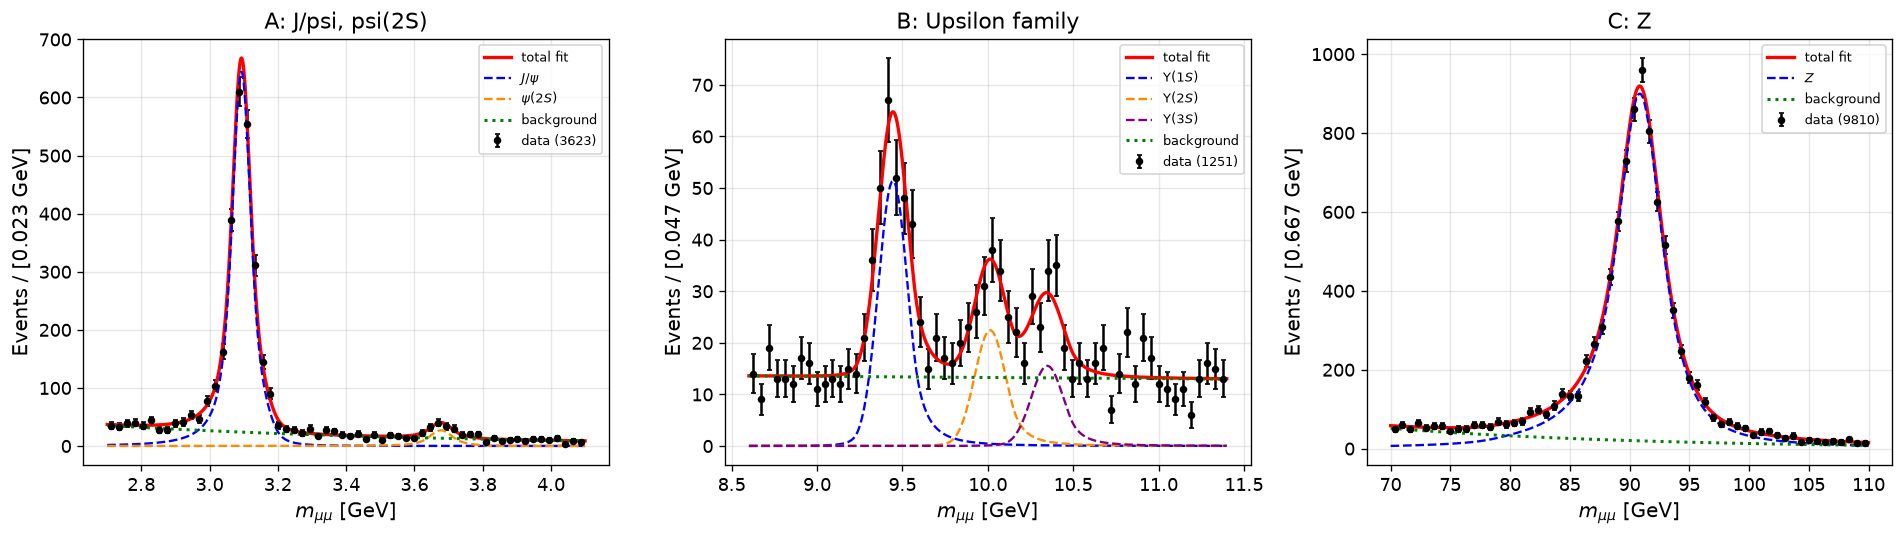

Region A: Poisson deviance = 51.3 for 60 bins and 11 parameters (ndof = 49, D/ndof = 1.05)
Region B: Poisson deviance = 46.5 for 60 bins and 11 parameters (ndof = 49, D/ndof = 0.95)
Region C: Poisson deviance = 52.4 for 60 bins and 9 parameters (ndof = 51, D/ndof = 1.03)


In [7]:
def plot_region(R, f, ax):
    p = f['values']
    scale = R.bin_width
    comps = R.components(p)
    colors = ['blue', 'darkorange', 'purple']
    tot = sum(y*fn for y, fn in comps)*scale
    ax.errorbar(R.bin_centers, R.counts, yerr=np.sqrt(R.counts), fmt='o', color='black', ms=3.5, capsize=1.5, label=f'data ({R.N})')
    ax.plot(R.xg, tot, 'r-', lw=2, label='total fit')
    for k in range(R.K):
        ax.plot(R.xg, comps[k][0]*comps[k][1]*scale, '--', color=colors[k], lw=1.4, label=PRETTY[R.peaks[k]])
    ax.plot(R.xg, comps[-1][0]*comps[-1][1]*scale, 'g:', lw=1.8, label='background')
    ax.set_xlabel(r'$m_{\mu\mu}$ [GeV]'); ax.set_ylabel(f'Events / [{R.bin_width:.3f} GeV]')
    ax.set_title(R.name); ax.legend(fontsize=8); ax.grid(alpha=0.3)
    return R.deviance(p)  # Poisson deviance over all bins

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
dev_unb = {}
for ax, key in zip(axes, ['A', 'B', 'C']):
    dev_unb[key] = plot_region(regions[key], fits[key], ax)
plt.tight_layout(); plt.show()

for key, R in regions.items():
    ndof = R.ndof
    print(f"Region {key}: Poisson deviance = {dev_unb[key]:.1f} for {R.nbins} bins and {len(R.names)} parameters "
          f"(ndof = {ndof}, D/ndof = {dev_unb[key]/ndof:.2f})")

### What was done: mass extraction
For every peak the fit gives the mass, its error and the yield. The printout above shows the fitted masses and how far they are from the PDG values, and also the fitted $Z$ width. The red curve in each window follows the data.

---
## 5. Discovery tests

For each peak $k$, $H_0$ is $N_k = 0$ and $H_1$ is $N_k > 0$ with $m_k$ free. The test statistic is
$$q_0 = 2\left[(-\ln L_{H_0}) - (-\ln L_{\text{MLE}})\right], \qquad Z_0 \simeq \sqrt{q_0}$$
In the null fit I fix the yield to zero, put $m_k$ at its PDG value (the mass has no meaning without a peak) and refit everything else.

Wilks' theorem is only approximately valid here, because $N_k = 0$ is on the boundary of the allowed region and the mass only exists under $H_1$. So for the weak peaks $Z_0$ should be taken as a rough guide only.

In [8]:
def nested_test(R, full, fix):
    # refit with some parameters fixed, returns q, sqrt(q), fit
    st = {k: v for k, v in full['values'].items() if k not in fix}
    f0 = R.fit(fix=fix, start=st)
    q = max(0.0, 2*(f0['fval'] - full['fval']))
    return q, np.sqrt(q), f0

def null_fix(R, k, full):
    # null fit for peak k: N_k = 0, m_k at PDG. for a one-peak region the shape parameters are frozen too
    fix = {f'n{k}': 0.0, f'm{k}': R.M[k]}
    if R.K == 1:
        for name in R.signal_shape_names:      # sig, alpha, alphaR, fg, rg, gam
            fix[name] = full['values'][name]
    return fix

disc = {}
print("=" * 82)
print(f"{'particle':<10}{'region':<8}{'N fit':>10}{'q0':>14}{'Z0 (asympt.)':>16}{'p-value':>14}")
print("=" * 82)
for key, R in regions.items():
    for k in range(R.K):
        q, z, f0 = nested_test(R, fits[key], null_fix(R, k, fits[key]))
        p = 0.5*stats.chi2.sf(q, 1)
        disc[(key, k)] = dict(q=q, z=z, p=p)
        print(f"{R.peaks[k]:<10}{key:<8}{fits[key]['values'][f'n{k}']:>10.1f}{q:>14.1f}{z:>13.1f} sigma{p:>14.2e}")
print("=" * 82)

particle  region       N fit            q0    Z0 (asympt.)       p-value
J/psi     A           2366.8        5245.2         72.4 sigma      0.00e+00
psi(2S)   A            118.2          72.0          8.5 sigma      1.06e-17
Y(1S)     B            253.9         188.7         13.7 sigma      3.05e-43
Y(2S)     B            117.3          54.7          7.4 sigma      7.05e-14
Y(3S)     B             83.8          27.9          5.3 sigma      6.25e-08
Z         C           8415.4       13040.1        114.2 sigma      0.00e+00


### What was done: discovery test
I removed each peak (yield set to 0) and compared the likelihood with the full fit. The likelihood ratio gives $q_0$ and $Z_0=\sqrt{q_0}$. The table above lists the significance of each peak.

---
## 6. Mass tests

Every particle has its own mass parameter $m_k$, so for each peak the test is $H_0$: $m_k = M_k^{\text{PDG}}$ against the free fit,
$$q(m_0) = 2\left[(-\ln L(m_k = m_0)) - (-\ln L_{\text{MLE}})\right], \qquad Z = \sqrt{q}$$
with all other parameters (including the other masses) refitted. After that I do a profile-likelihood scan of the mass of each of the four main particles at 15 values, with the PDG value and the best-fit value marked. For the $Z$ I also test the width, $H_0: \Gamma = 2.4952$ GeV.

The errors are statistical only. So if the mass is far from the PDG value, it most likely points to a systematic effect (momentum scale, line shape) and not to a real mass difference.

In [9]:
# test of m_k = PDG for every peak
mass_test = {}
print("=" * 100)
print(f"{'particle':<10}{'m fit [GeV]':>14}{'stat. error [GeV]':>20}{'offset [MeV]':>15}{'q(PDG)':>10}{'Z':>10}{'p-value':>12}")
print("=" * 100)
for key, R in regions.items():
    for k in range(R.K):
        q, z, f0 = nested_test(R, fits[key], {f'm{k}': R.M[k]})
        v, e = fits[key]['values'], fits[key]['errors']
        mass_test[(key, k)] = dict(q=q, z=z, p=stats.chi2.sf(q, 1))
        print(f"{R.peaks[k]:<10}{v[f'm{k}']:>14.4f}{e[f'm{k}']:>20.4f}{1000*(v[f'm{k}'] - R.M[k]):>15.1f}"
              f"{q:>10.1f}{z:>7.1f} sigma{stats.chi2.sf(q, 1):>12.2e}")
print("=" * 100)

# Z width test
q_w, z_w, _ = nested_test(regions['C'], fits['C'], {'gam': GAMMA_Z_PDG})
gv, ge = fits['C']['values']['gam'], fits['C']['errors']['gam']
print(f"\nZ natural width: fit {gv:.3f} +/- {ge:.3f} GeV, PDG {GAMMA_Z_PDG}:  q = {q_w:.2f}, Z = {z_w:.2f} sigma")

particle     m fit [GeV]   stat. error [GeV]   offset [MeV]    q(PDG)         Z     p-value
J/psi             3.0935              0.0009           -3.4      14.7    3.8 sigma    1.24e-04
psi(2S)           3.6775              0.0066           -8.6       1.6    1.3 sigma    2.04e-01
Y(1S)             9.4442              0.0085          -16.1       3.5    1.9 sigma    6.12e-02
Y(2S)            10.0134              0.0159           -9.9       0.4    0.6 sigma    5.41e-01
Y(3S)            10.3479              0.0203           -7.3       0.1    0.4 sigma    7.21e-01
Z                90.8594              0.0506         -328.2       8.8    3.0 sigma    2.99e-03

Z natural width: fit 2.839 +/- 0.424 GeV, PDG 2.4952:  q = 0.64, Z = 0.80 sigma


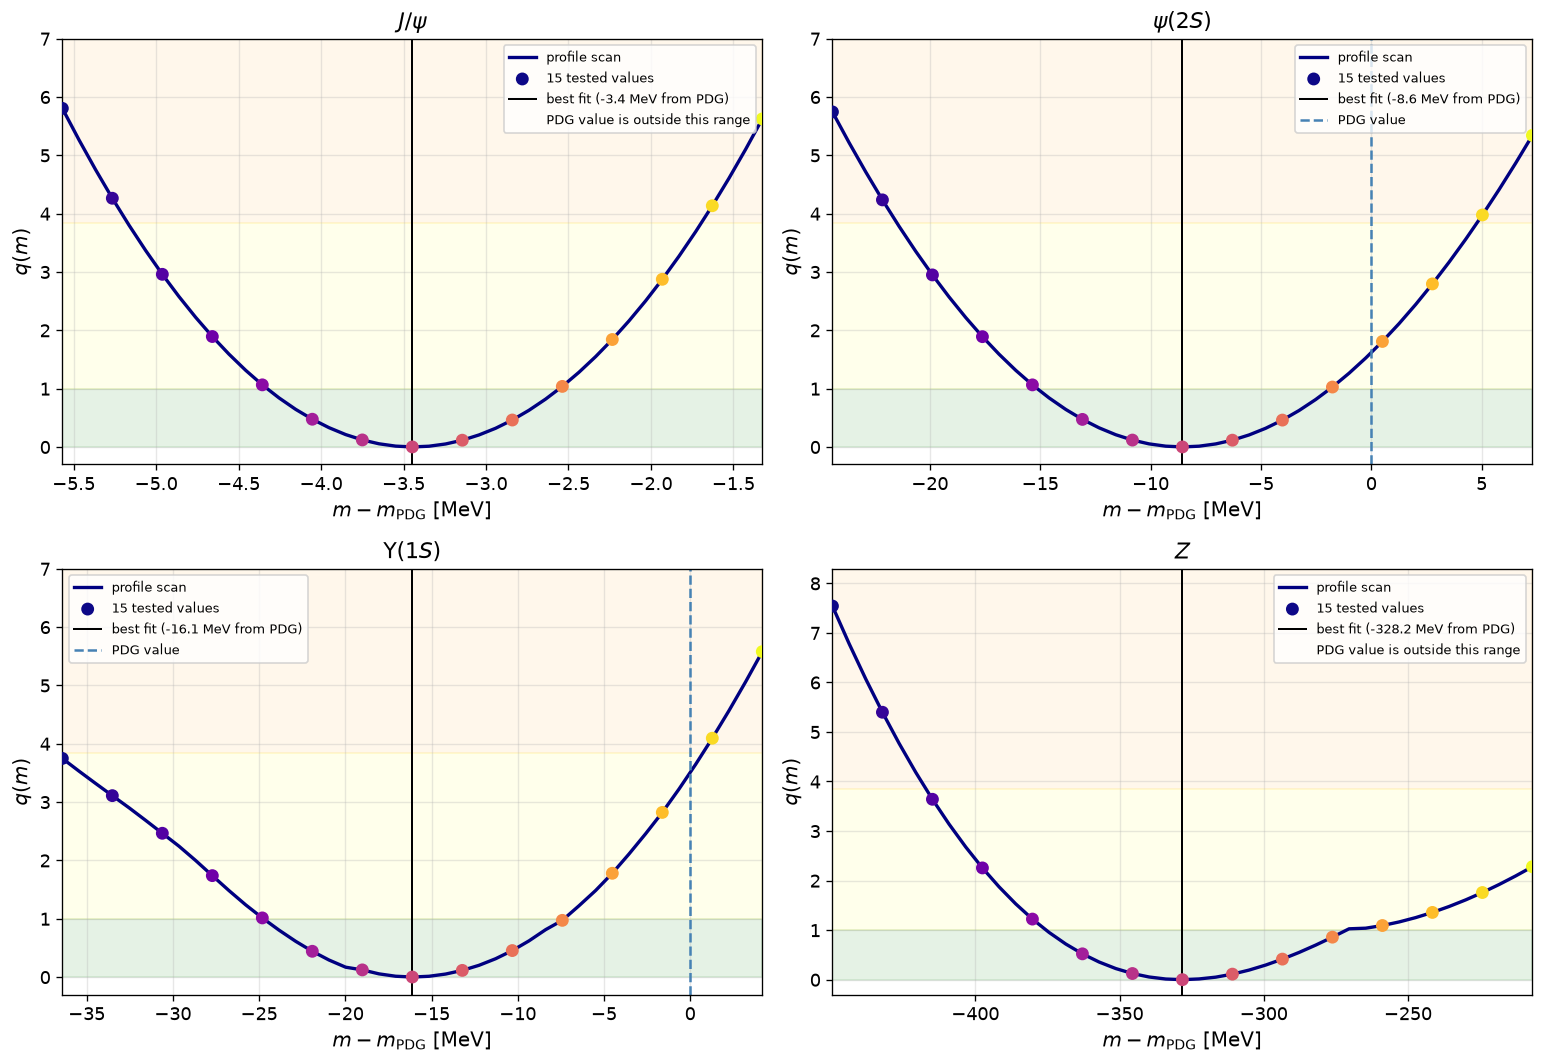

15-point scans over best fit +/- 2.4 sigma (significance Z = sqrt(q) of excluding each mass value):

J/psi
   offset from PDG [MeV]      -5.6     -5.3     -5.0     -4.7     -4.4     -4.1     -3.8     -3.4     -3.1     -2.8     -2.5     -2.2     -1.9     -1.6     -1.3
   Z [sigma]                   2.4      2.1      1.7      1.4      1.0      0.7      0.3      0.0      0.3      0.7      1.0      1.4      1.7      2.0      2.4

psi(2S)
   offset from PDG [MeV]     -24.4    -22.1    -19.9    -17.6    -15.4    -13.1    -10.8     -8.6     -6.3     -4.0     -1.8      0.5      2.8      5.0      7.3
   Z [sigma]                   2.4      2.1      1.7      1.4      1.0      0.7      0.3      0.0      0.3      0.7      1.0      1.3      1.7      2.0      2.3

Y(1S)
   offset from PDG [MeV]     -36.4    -33.5    -30.6    -27.7    -24.8    -21.9    -19.0    -16.1    -13.2    -10.3     -7.4     -4.5     -1.6      1.3      4.2
   Z [sigma]                   1.9      1.8      1.6      1.3      1.0  

In [10]:
# profile-likelihood scan of the mass of the four main particles (15 tested values each)
# range: best-fit mass +/- 2.4 sigma  (sigma = statistical error on the mass)
NSIG = 1.2*2
scan = {}
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (key, k) in zip(axes.ravel(), MAIN):
    R = regions[key]
    v, e = fits[key]['values'], fits[key]['errors']
    mn = f'm{k}'
    err = e[mn] if (np.isfinite(e[mn]) and e[mn] > 0) else 0.002*R.M[k]
    lo_m = max(v[mn] - NSIG*err, R.M[k]*(1 - R.mw) + 1e-6)    # stay inside the allowed mass window
    hi_m = min(v[mn] + NSIG*err, R.M[k]*(1 + R.mw) - 1e-6)
    fine = np.linspace(lo_m, hi_m, 43)                        # 43 points: every 3rd one gives the 15 tested values
    qf = np.array([nested_test(R, fits[key], {mn: x})[0] for x in fine])
    g15, q15 = fine[::3], qf[::3]
    scan[(key, k)] = (g15, q15)
    off = 1000*(fine - R.M[k])                                # offset from the PDG mass [MeV]
    best = 1000*(v[mn] - R.M[k])
    ax.plot(off, qf, '-', color='navy', lw=2, label='profile scan')
    ax.scatter(off[::3], q15, c=np.arange(len(q15)), cmap='plasma', s=45, zorder=5, label='15 tested values')
    ax.axhspan(0, 1, alpha=0.1, color='green'); ax.axhspan(1, 3.84, alpha=0.08, color='yellow'); ax.axhspan(3.84, 9, alpha=0.08, color='orange')
    ax.axvline(best, color='black', lw=1.2, label=f'best fit ({best:+.1f} MeV from PDG)')
    if off.min() <= 0.0 <= off.max():
        ax.axvline(0.0, color='steelblue', ls='--', lw=1.5, label='PDG value')
    else:
        ax.plot([], [], ' ', label='PDG value is outside this range')
    ax.set_xlim(off.min(), off.max())
    ax.set_ylim(-0.3, max(7.0, 1.1*qf.max()))
    ax.set_xlabel(r'$m - m_{\mathrm{PDG}}$ [MeV]'); ax.set_ylabel(r'$q(m)$')
    ax.set_title(PRETTY[R.peaks[k]]); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"15-point scans over best fit +/- {NSIG:.1f} sigma (significance Z = sqrt(q) of excluding each mass value):")
for key, k in MAIN:
    R = regions[key]
    g, q = scan[(key, k)]
    print(f"\n{R.peaks[k]}")
    print("   offset from PDG [MeV]  " + " ".join(f"{1000*(x - R.M[k]):8.1f}" for x in g))
    print("   Z [sigma]              " + " ".join(f"{np.sqrt(x):8.1f}" for x in q))


### What was done: mass test
Each mass was fixed at its PDG value and refitted, and the increase in $-\ln L$ was converted to a significance. The scan plot shows the same thing for 15 mass values around the best fit. A large offset with a very small statistical error (for example the $J/\psi$ and the $Z$) points to a systematic effect, like the muon momentum scale that I did not correct, and not to a real mass difference.

### 6.1 $\Upsilon$ mass splittings ($\Delta m_{21}$, $\Delta m_{31}$)

The absolute masses depend on the muon momentum scale, which is not corrected here. If all momenta are wrong by the same relative amount $\delta$, every fitted mass moves like
$$m_k^{\text{fit}} \approx (1 + \delta)\, M_k^{\text{PDG}}, \qquad \Delta m_{k1}^{\text{fit}} = m_k^{\text{fit}} - m_1^{\text{fit}} \approx \Delta M_{k1}^{\text{PDG}} + \delta\,\Delta M_{k1}^{\text{PDG}}.$$
With $\Delta M_{21} \approx 0.563$ GeV and $\Delta M_{31} \approx 0.895$ GeV, the splittings only move by $\delta \cdot 0.56$ GeV and $\delta \cdot 0.90$ GeV. That is about 6 % and 9 % of the shift of the $\Upsilon(1S)$ mass ($\delta \cdot 9.46$ GeV). So most of a common scale error cancels in the splittings, which makes them a cleaner test than the absolute masses.

For $k = 2, 3$ the test is $H_0: \Delta m_{k1} = \Delta M_{k1}^{\text{PDG}}$, and I do it in two ways:
* Gaussian error from the Minuit covariance, $\text{Var}(m_k - m_1) = \text{Var}(m_k) + \text{Var}(m_1) - 2\,\text{Cov}(m_k, m_1)$,
* profile likelihood $q(\Delta m_{k1})$, refitting with $m_k = m_1 + \Delta m_{k1}$ forced (the `tie` option of `Region.fit`) and everything else, including $m_1$, free.

The resolutions of the three states are tied by $\sigma_k = \sigma\, M_k/M_1$ and they share the tail parameters, so the result depends on this assumption.

splitting        fit [MeV]  cov. error   PDG [MeV]  fit-PDG [MeV]  q(PDG) profile      Z
dm(2S-1S)           569.3        18.2       563.0            6.3            0.12   0.34
dm(3S-1S)           903.7        22.4       894.9            8.8            0.15   0.39


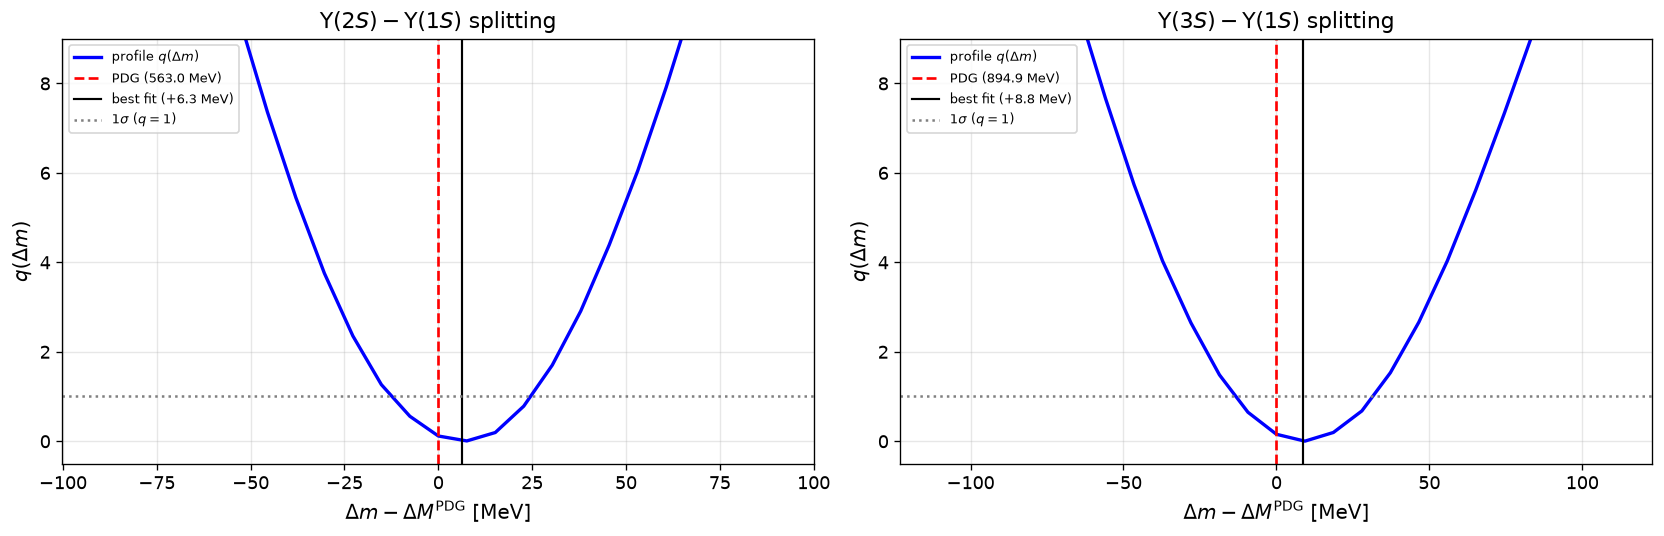

for comparison, the absolute Y(1S) mass offset is -16.1 +/- 8.5 MeV (stat), i.e. -0.170 % relative.
A common scale error delta moves the splittings by delta*dM and Y(1S) by delta*M, so for delta = 0.1 %:
  Y(1S) mass: 9.5 MeV,   dm21: 0.56 MeV,   dm31: 0.89 MeV


In [11]:
# mass splittings of the Upsilon family: error from the covariance + profile likelihood with m_k = m_1 + delta
RB, fB = regions['B'], fits['B']
vB = fB['values']
covB = fB['m'].covariance            # None if HESSE failed

def split_profile_q(k, delta):
    # q for m_k - m_0 = delta, all other parameters refitted
    st = {n: x for n, x in vB.items() if n != f'm{k}'}
    f0 = RB.fit(start=st, tie=(k, 0, delta))
    return max(0.0, 2*(f0['fval'] - fB['fval']))

split_res = {}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
print("=" * 96)
print(f"{'splitting':<14}{'fit [MeV]':>12}{'cov. error':>12}{'PDG [MeV]':>12}{'fit-PDG [MeV]':>15}{'q(PDG) profile':>16}{'Z':>7}")
print("=" * 96)
for ax, k in zip(axes, (1, 2)):
    d_fit, d_pdg = vB[f'm{k}'] - vB['m0'], RB.M[k] - RB.M[0]
    if covB is not None:
        err = np.sqrt(max(1e-12, covB[f'm{k}', f'm{k}'] + covB['m0', 'm0'] - 2*covB[f'm{k}', 'm0']))
    else:
        err = np.hypot(fB['errors'][f'm{k}'], fB['errors']['m0'])       # fallback: no correlation
    q_pdg = split_profile_q(k, d_pdg)
    split_res[k] = dict(fit=d_fit, err=err, pdg=d_pdg, q=q_pdg, z=np.sqrt(q_pdg))
    print(f"dm({k+1}S-1S){'':<4}{1000*d_fit:>12.1f}{1000*err:>12.1f}{1000*d_pdg:>12.1f}{1000*(d_fit - d_pdg):>15.1f}"
          f"{q_pdg:>16.2f}{np.sqrt(q_pdg):>7.2f}")
    half = max(5*err, 0.01)
    grid = np.linspace(d_pdg - half, d_pdg + half, 25)
    qs = np.array([split_profile_q(k, d) for d in grid])
    ax.plot(1000*(grid - d_pdg), qs, 'b-', lw=2, label=r'profile $q(\Delta m)$')
    ax.axvline(0.0, color='red', ls='--', lw=1.6, label=f'PDG ({1000*d_pdg:.1f} MeV)')
    ax.axvline(1000*(d_fit - d_pdg), color='black', lw=1.3, label=f'best fit ({1000*(d_fit - d_pdg):+.1f} MeV)')
    ax.axhline(1.0, color='gray', ls=':', label=r'$1\sigma$ ($q = 1$)')
    ax.set_ylim(-0.5, 9); ax.set_xlabel(r'$\Delta m - \Delta M^{\mathrm{PDG}}$ [MeV]'); ax.set_ylabel(r'$q(\Delta m)$')
    ax.set_title(rf'$\Upsilon({k+1}S) - \Upsilon(1S)$ splitting'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
print("=" * 96)
plt.tight_layout(); plt.show()

off1, e1 = 1000*(vB['m0'] - RB.M[0]), 1000*fB['errors']['m0']
print(f"for comparison, the absolute Y(1S) mass offset is {off1:+.1f} +/- {e1:.1f} MeV (stat), i.e. {100*(vB['m0'] - RB.M[0])/RB.M[0]:+.3f} % relative.")
print("A common scale error delta moves the splittings by delta*dM and Y(1S) by delta*M, so for delta = 0.1 %:")
print(f"  Y(1S) mass: {1000*1e-3*RB.M[0]:.1f} MeV,   dm21: {1000*1e-3*(RB.M[1]-RB.M[0]):.2f} MeV,   dm31: {1000*1e-3*(RB.M[2]-RB.M[0]):.2f} MeV")

---
## 7. Likelihood surfaces and contours

Here I look at $-2\Delta\ln L$ as a function of two parameters: the mass of the main peak of each region ($J/\psi$, $\Upsilon(1S)$, $Z$) and the resolution $\sigma$. At every grid point all the other parameters are refitted, so these are profile-likelihood contours. For two parameters the levels are $\Delta q = 2.30,\ 6.18,\ 11.83$ for $1,\ 2,\ 3\sigma$. The grid is small ($\text{GRID\_N} \times \text{GRID\_N}$) to keep the run time low.

Profiled grids computed in 283 s


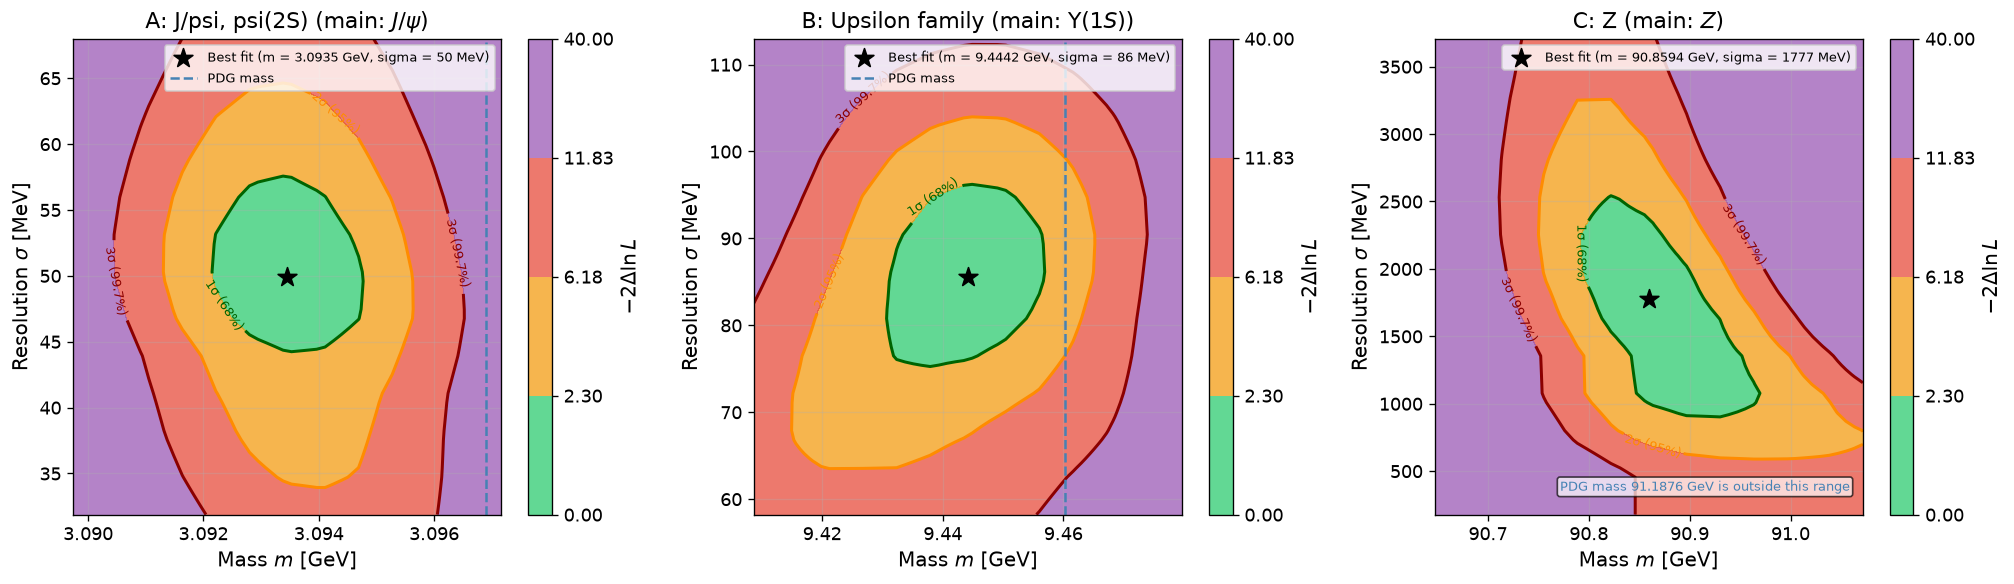

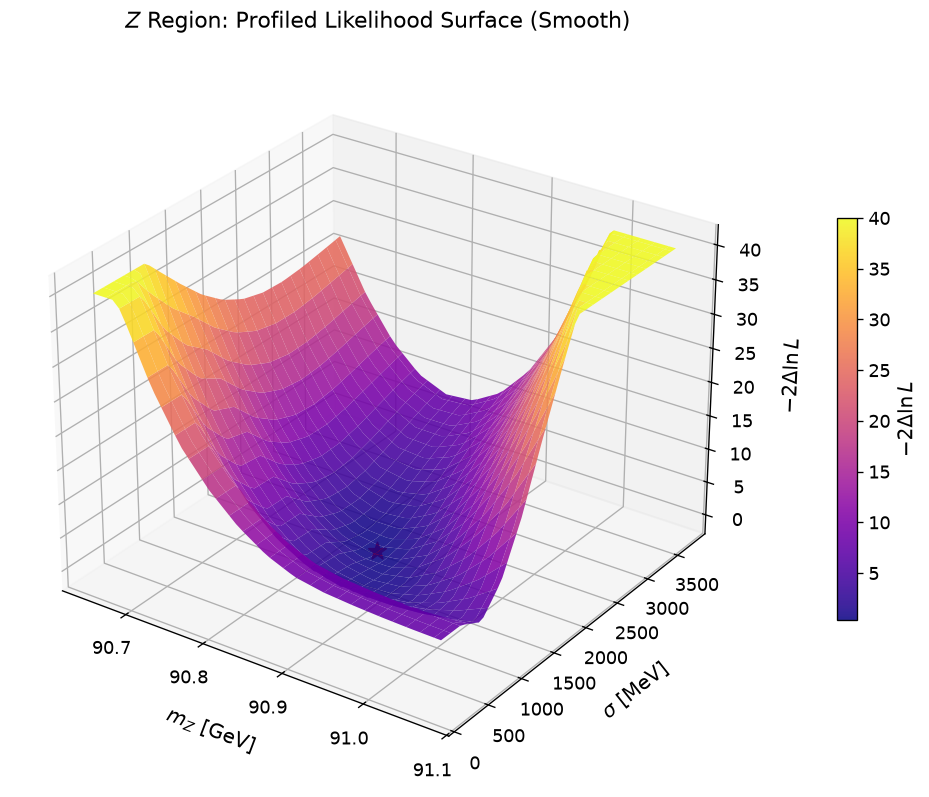

In [13]:
from scipy.ndimage import zoom

LV = [2.30, 6.18, 11.83]
FILL_LEVS = [0] + LV + [40]
FILL_COLS = ['#2ecc71', '#f39c12', '#e74c3c', '#9b59b6']

# finer grid and wider range so the contours are smooth and not cut off
GRID_CONTOUR = 13
grids = {}
t0 = time.time()
for key, R in regions.items():
    v, e = fits[key]['values'], fits[key]['errors']
    em = e['m0'] if (np.isfinite(e['m0']) and e['m0'] > 0) else 0.002*R.M[0]
    es = e['sig'] if (np.isfinite(e['sig']) and e['sig'] > 0) else 0.1*R.sig_guess
    
    # 4.2 sigma range so the 3 sigma contour (dq = 11.83) fits inside the plot
    mx = np.linspace(v['m0'] - 4.2*em, v['m0'] + 4.2*em, GRID_CONTOUR)
    s_min = max(0.1*v['sig'], v['sig'] - 4.2*es)
    s_max = v['sig'] + 4.2*es
    sy = np.linspace(s_min, s_max, GRID_CONTOUR)
    
    dq = np.zeros((GRID_CONTOUR, GRID_CONTOUR))
    base = {k: val for k, val in v.items() if k not in ('m0', 'sig')}
    prev_row = [base]*GRID_CONTOUR                       # best parameters found at the grid point below
    for i, y in enumerate(sy):
        prev = base
        for j, x in enumerate(mx):
            # two starting points: the global best fit, and the neighbouring grid point -> keep the lower -lnL
            f_a = R.fit(fix={'m0': x, 'sig': y}, start=base)
            f_b = R.fit(fix={'m0': x, 'sig': y}, start=prev if j > 0 else prev_row[j])
            f = f_a if f_a['fval'] <= f_b['fval'] else f_b
            prev = {k: val for k, val in f['values'].items() if k not in ('m0', 'sig')}
            prev_row[j] = prev
            dq[i, j] = max(0.0, 2*(f['fval'] - fits[key]['fval']))
    grids[key] = (mx, sy, dq)
print(f"Profiled grids computed in {time.time()-t0:.0f} s")

# 2D profile likelihood contours (interpolated to look smooth)
fig, axes = plt.subplots(1, 3, figsize=(17, 5.0))
for ax, (key, R) in zip(axes, regions.items()):
    mx, sy, dq = grids[key]
    
    # interpolate onto a denser grid so the contours look smooth
    dq_smooth = zoom(dq, 4, order=1)
    mx_dense = np.linspace(mx.min(), mx.max(), dq_smooth.shape[1])
    sy_dense = np.linspace(sy.min(), sy.max(), dq_smooth.shape[0])
    
    XX, YY = np.meshgrid(mx_dense, 1000*sy_dense)          # x axis: absolute mass in GeV
    cf = ax.contourf(XX, YY, np.clip(dq_smooth, 0, 40), levels=FILL_LEVS, colors=FILL_COLS, alpha=0.75)
    cs = ax.contour(XX, YY, dq_smooth, levels=LV, colors=['darkgreen', 'darkorange', 'darkred'], linewidths=1.8)
    ax.clabel(cs, inline=True, fontsize=8, fmt={2.30: '1σ (68%)', 6.18: '2σ (95%)', 11.83: '3σ (99.7%)'})
    
    best_m = fits[key]['values']['m0']                       # best-fit mass [GeV]
    best_s = fits[key]['values']['sig']*1000
    ax.scatter(best_m, best_s, color='black', marker='*', s=140, zorder=10, label=f'Best fit (m = {best_m:.4f} GeV, sigma = {best_s:.0f} MeV)')
    
    # draw the PDG line if it is inside the plot, otherwise write a note
    x_lo, x_hi = mx_dense.min(), mx_dense.max()
    if x_lo <= R.M[0] <= x_hi:
        ax.axvline(R.M[0], color='steelblue', ls='--', lw=1.5, label='PDG mass')
    else:
        ax.text(0.97, 0.05, f'PDG mass {R.M[0]:.4f} GeV is outside this range', transform=ax.transAxes,
                ha='right', fontsize=8, color='steelblue', bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7))
        
    ax.set_xlabel(r'Mass $m$ [GeV]')
    ax.set_ylabel(r'Resolution $\sigma$ [MeV]')
    ax.set_title(f"{R.name} (main: {PRETTY[R.peaks[0]]})")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc='upper right')
    plt.colorbar(cf, ax=ax, label=r'$-2\Delta\ln L$')

plt.tight_layout()
plt.show()

# 3D likelihood surface for region C (Z)
mx, sy, dq = grids['C']
dq_smooth = zoom(dq, 4, order=1)
mx_dense = np.linspace(mx.min(), mx.max(), dq_smooth.shape[1])
sy_dense = np.linspace(sy.min(), sy.max(), dq_smooth.shape[0])
XX, YY = np.meshgrid(mx_dense, 1000*sy_dense)

fig = plt.figure(figsize=(10, 6.8))
ax3 = fig.add_subplot(111, projection='3d')
surf = ax3.plot_surface(XX, YY, np.clip(dq_smooth, 0, 40), cmap='plasma', alpha=0.88, linewidth=0, antialiased=True)
best_m_z = fits['C']['values']['m0']
best_s_z = fits['C']['values']['sig']*1000
ax3.scatter([best_m_z], [best_s_z], [0], color='red', s=120, marker='*', zorder=10, label='MLE Minimum')

ax3.set_xlabel(r'$m_Z$ [GeV]', labelpad=10)
ax3.set_ylabel(r'$\sigma$ [MeV]', labelpad=10)
ax3.set_zlabel(r'$-2\Delta\ln L$', labelpad=8)
ax3.set_title(r'$Z$ Region: Profiled Likelihood Surface (Smooth)', pad=15)
ax3.view_init(28, -55)
fig.colorbar(surf, ax=ax3, shrink=0.55, pad=0.08, label=r'$-2\Delta\ln L$')
plt.tight_layout()
plt.show()


## 8. Binned fit 

So far, all the fits have been performed using the unbinned data, where the exact invariant mass of every event is used in the likelihood. As an independent cross-check, I repeat the fits using histograms of the invariant mass distributions.

The three mass regions are divided into 60 bins, respectively. Instead of using the mass of every individual event, the binned fit uses the number of events, $n_i$, observed in each bin.

For a given set of model parameters $\boldsymbol{\theta}$, the model predicts an expected number of events $\mu_i(\boldsymbol{\theta})$ in each bin. The observed number of events in that bin is assumed to follow a Poisson distribution:

$$
P(n_i|\mu_i)=
\frac{\mu_i^{n_i}e^{-\mu_i}}{n_i!}.
$$

Assuming that the bin counts are independent, the likelihood is the product of the Poisson probabilities over all bins:

$$
L(\boldsymbol{\theta})=
\prod_{i=1}^{K}
\frac{\mu_i(\boldsymbol{\theta})^{n_i}
e^{-\mu_i(\boldsymbol{\theta})}}{n_i!}.
$$

Taking the negative logarithm gives

$$
-\ln L =
\sum_{i=1}^{K}
\left[
\mu_i(\boldsymbol{\theta})
-n_i\ln\mu_i(\boldsymbol{\theta})
\right]
+\text{constant}.
$$

The constant term contains $\ln(n_i!)$, which does not depend on the model parameters. Therefore, it can be ignored during minimisation.

This is an **extended likelihood**, because the expected total number of events is also included in the model. In particular,

$$
\sum_i\mu_i = \sum_k N_k+N_B,
$$

where $N_k$ are the signal yields and $N_B$ is the background yield.

### Calculating the expected number of events in each bin

The expected number of events in a bin is obtained by integrating the signal and background probability densities over that bin:

$$
\mu_i =
\sum_k N_k\int_{a_i}^{b_i}P_k(m)\,dm
+
N_B\int_{a_i}^{b_i}B(m)\,dm.
$$

Here, $a_i$ and $b_i$ are the lower and upper edges of the bin. The integral gives the fraction of the corresponding distribution that falls inside the bin. Multiplying it by the corresponding yield gives the expected number of events.

In the code, this calculation is performed in the function `expected_bins`. The probability densities are evaluated at 40 points inside each bin and numerically summed to estimate the integral.

This is more accurate than simply evaluating the PDF at the bin centre and multiplying by the bin width. The latter approximation assumes that the PDF is almost constant across the bin. This assumption can become inaccurate near the top of a narrow resonance peak, where the probability density changes rapidly.

### Goodness of fit: Poisson deviance

After obtaining the best-fit parameters, I check how well the model describes the observed histogram. For this, I use the **Poisson deviance**, which compares the fitted model with a saturated model.

The saturated model is a reference model in which every bin is assigned an expected value equal to its observed count:

$$
\mu_i=n_i.
$$

In other words, it reproduces the observed histogram exactly. It is not a physical model; it simply provides the best possible agreement with the data on a bin-by-bin basis.

The Poisson deviance measures how much worse the fitted model is compared with this saturated model:

$$
D =
2\sum_i
\left[
\mu_i-n_i+
n_i\ln\left(\frac{n_i}{\mu_i}\right)
\right].
$$

For bins with zero observed events, the logarithmic term is taken to be zero.

A smaller deviance indicates better agreement between the model and the data. When the expected bin counts are sufficiently large, the deviance approximately follows a chi-square distribution, with degrees of freedom given by

$$
\mathrm{ndof}=K-N_{\mathrm{par}},
$$

where $K$ is the number of bins and $N_{\mathrm{par}}$ is the number of fitted parameters. Therefore, a value of

$$
\frac{D}{\mathrm{ndof}}\approx 1
$$

is generally consistent with a reasonable fit.

However, this chi-square interpretation is only approximate. Some bins around the narrow $\psi(2S)$ and $\Upsilon$ peaks contain very few events, so the large-count approximation is not fully satisfied there. The deviance is still useful as a goodness-of-fit measure, but its ratio to the number of degrees of freedom should not be interpreted too strictly.


In [19]:
binned_fits = {}
for key, R in regions.items():
    fb = R.fit(binned=True, start=fits[key]['values'])
    binned_fits[key] = fb
    mu = R.expected_bins(fb['values'])
    dev = R.deviance(fb['values'])
    ndof = R.ndof
    pv = stats.chi2.sf(dev, ndof)
    print(f"=== Region {R.name}: binned vs unbinned ===")
    print(f"{'param':<7}{'binned':>24}{'unbinned':>26}{'diff':>10}")
    for k in R.names:
        vb, eb = fb['values'][k], fb['errors'][k]
        vu, eu = fits[key]['values'][k], fits[key]['errors'][k]
        d_ = (vb - vu)
        print(f"{k:<7}{vb:>12.4f} +/- {eb:<9.4f}{vu:>12.4f} +/- {eu:<9.4f}{d_:>10.2f}")
    print(f"Poisson deviance / ndof = {dev:.1f} / {ndof} = {dev/ndof:.2f}   (p = {pv:.3f})\n")

=== Region A: J/psi, psi(2S): binned vs unbinned ===
param                    binned                  unbinned      diff
n0        2361.6969 +/- 67.1295     2366.8249 +/- 66.4750       -5.13
n1         118.6504 +/- 17.3556      118.2294 +/- 17.3276        0.42
nb        1142.7162 +/- 62.2111     1137.9420 +/- 61.2803        4.77
m0           3.0936 +/- 0.0009         3.0935 +/- 0.0009         0.00
m1           3.6806 +/- 0.0066         3.6775 +/- 0.0066         0.00
sig          0.0489 +/- 0.0048         0.0499 +/- 0.0043        -0.00
alpha        1.3386 +/- 0.1625         1.3248 +/- 0.1492         0.01
alphaR       2.0362 +/- 0.2919         2.0807 +/- 0.2862        -0.04
fg           0.4027 +/- 0.0946         0.4132 +/- 0.0782        -0.01
rg           0.4681 +/- 0.0394         0.4467 +/- 0.0326         0.02
lam          1.0169 +/- 0.1000         1.0030 +/- 0.0996         0.01
Poisson deviance / ndof = 50.5 / 49 = 1.03   (p = 0.412)

=== Region B: Upsilon family: binned vs unbinned ==

### 8.1 Visualising the binned likelihood

Three pictures to show what the binned fit does:
1. **Data vs model per bin:** the black points are the bin counts $n_i$ and the red steps are the fitted expectation $\mu_i$ in each bin. The binned likelihood is built only from these numbers.
2. **Likelihood of a single bin:** for one bin with $n_i$ events, $L_i(\mu)=\mu^{n_i}e^{-\mu}/n_i!$ is a Poisson curve in $\mu$. It peaks at $\mu=n_i$. The red line is the $\mu_i$ predicted by the fit. The full binned likelihood is the product of these curves over all bins.
3. **Binned vs unbinned profile likelihood** of the main-peak mass: if binning loses only a little information, the two curves should lie almost on top of each other (the binned one is a bit wider).

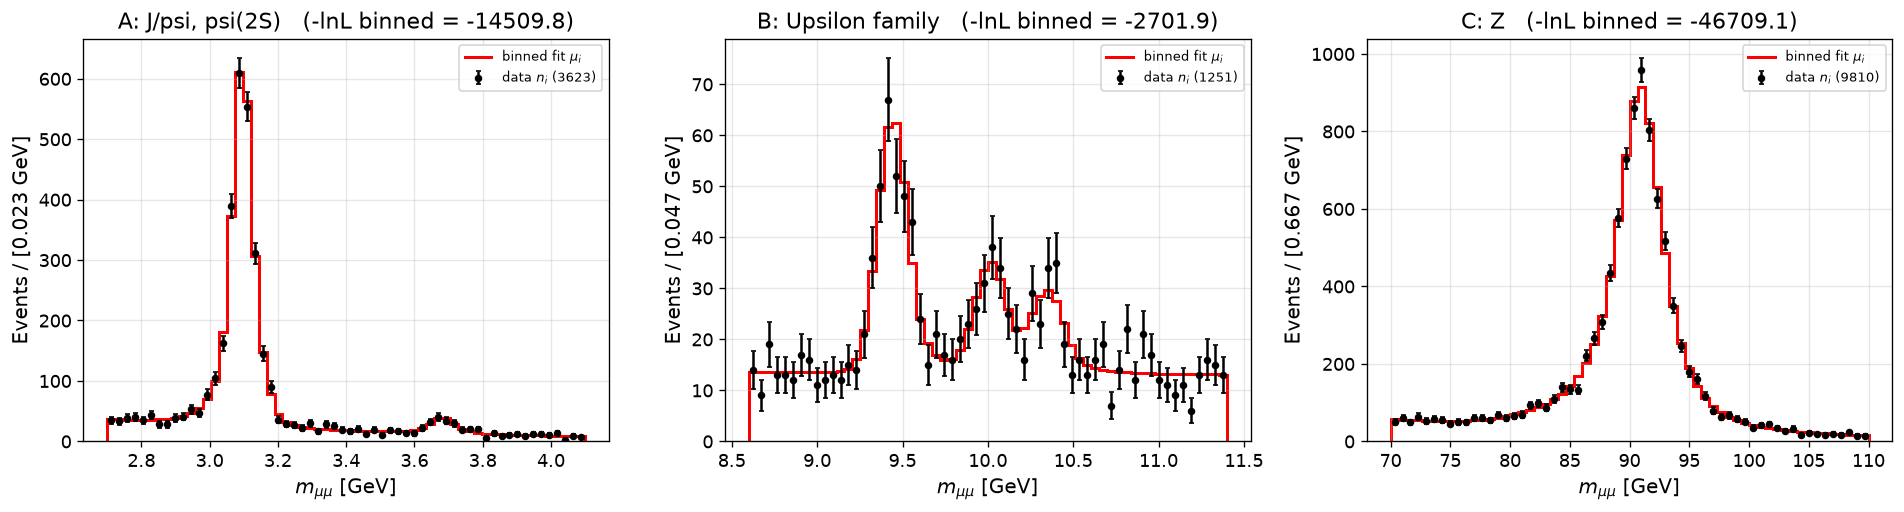

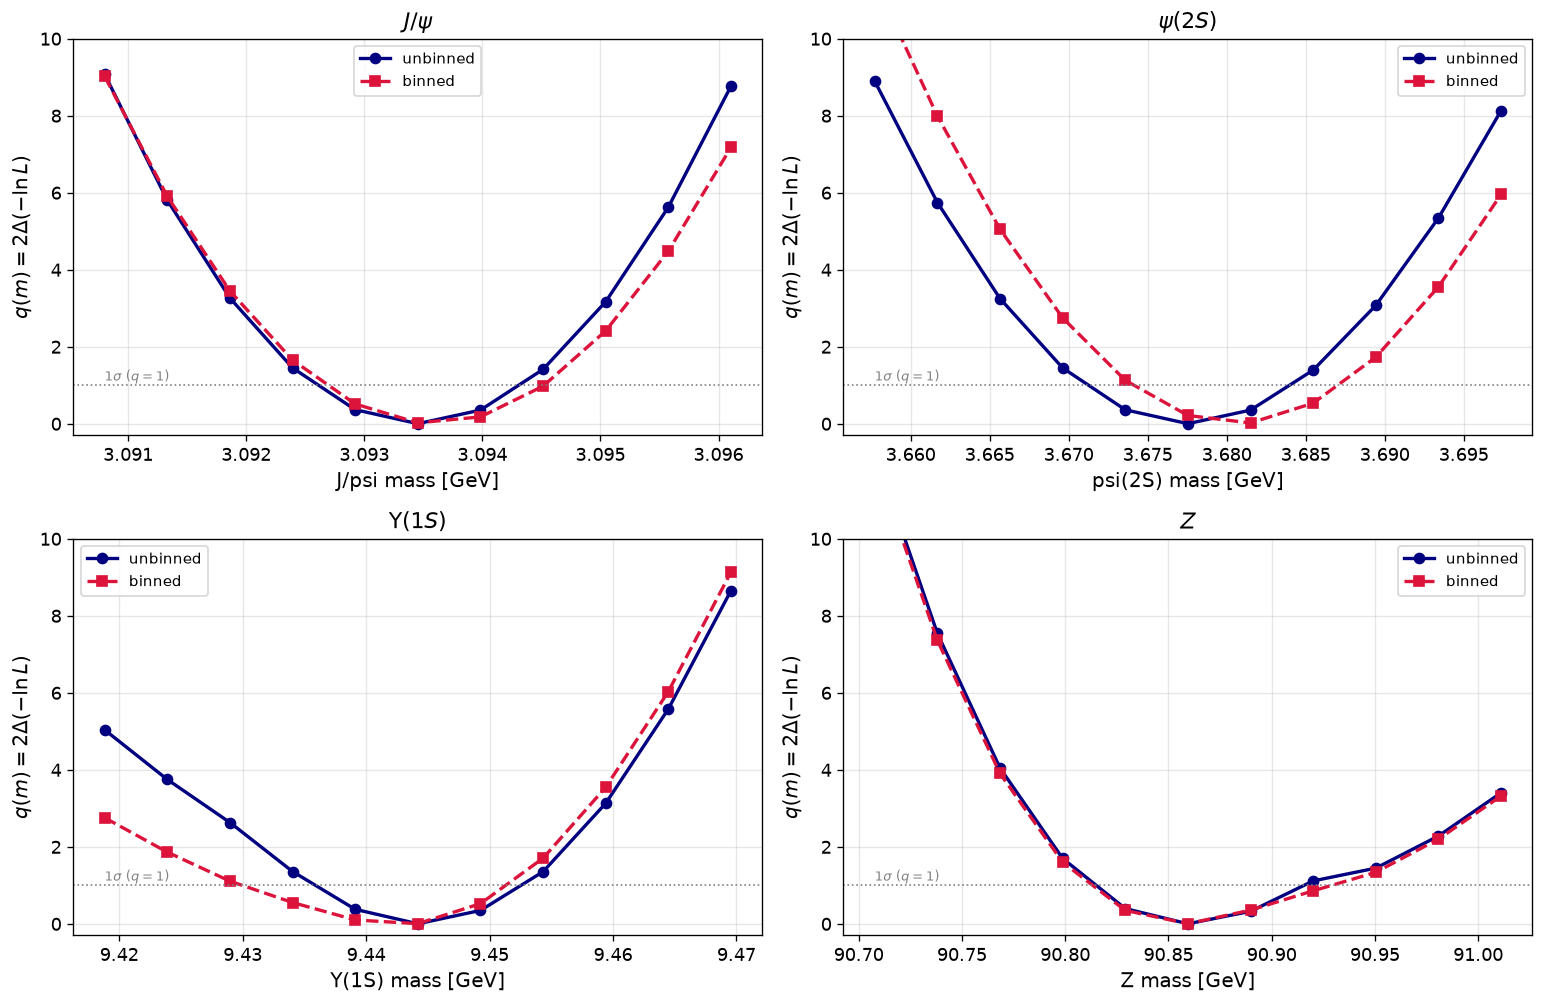

In [18]:
# ---- 1. data vs fitted bin expectation (binned fit) ----
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, (key, R) in zip(axes, regions.items()):
    pb = binned_fits[key]['values']
    mu = R.expected_bins(pb)
    edges = R.bin_edges
    ax.errorbar(R.bin_centers, R.counts, yerr=np.sqrt(R.counts), fmt='o', color='black', ms=3.5, capsize=1.5, label=f'data $n_i$ ({R.N})')
    ax.stairs(mu, edges, color='red', lw=1.8, label=r'binned fit $\mu_i$')
    ax.set_xlabel(r'$m_{\mu\mu}$ [GeV]'); ax.set_ylabel(f'Events / [{R.bin_width:.3f} GeV]')
    ax.set_title(f'{R.name}   (-lnL binned = {binned_fits[key]["fval"]:.1f})'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


# ---- 2. profile likelihood of the main-peak mass: binned vs unbinned ----
NPT = 11
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
for ax, (key, k) in zip(axes.ravel(), MAIN):
    R = regions[key]
    v, e = fits[key]['values'], fits[key]['errors']
    vb = binned_fits[key]['values']
    mn = f'm{k}'
    err = e[mn] if (np.isfinite(e[mn]) and e[mn] > 0) else 0.002*R.M[k]
    grid = np.linspace(v[mn] - 3*err, v[mn] + 3*err, NPT)
    grid = np.clip(grid, R.M[k]*(1 - R.mw) + 1e-6, R.M[k]*(1 + R.mw) - 1e-6)
    q_unb = np.array([nested_test(R, fits[key], {mn: x})[0] for x in grid])
    st = {n_: x_ for n_, x_ in vb.items() if n_ != mn}
    q_bin = np.array([2*(R.fit(binned=True, fix={mn: x}, start=st)['fval'] - binned_fits[key]['fval']) for x in grid])
    q_bin = np.maximum(q_bin, 0.0)
    ax.plot(grid, q_unb, 'o-', color='navy', lw=2, label='unbinned')
    ax.plot(grid, q_bin, 's--', color='crimson', lw=2, label='binned')
    ax.axhline(1.0, color='gray', ls=':', lw=1); ax.text(grid[0], 1.1, r'$1\sigma$ ($q=1$)', fontsize=8, color='gray')
    ax.set_ylim(-0.3, 10)
    ax.set_xlabel(f'{R.peaks[k]} mass [GeV]'); ax.set_ylabel(r'$q(m)=2\Delta(-\ln L)$')
    ax.set_title(PRETTY[R.peaks[k]]); ax.grid(alpha=0.3); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()


### References

1. M. J. Oreglia, *A Study of the Reactions $\psi' \rightarrow \gamma\gamma\psi$*, PhD thesis, SLAC-R-236 (1980), Appendix D.  
   [SLAC-R-236](https://slac.stanford.edu/pubs/slacreports/reports13/slac-r-236.pdf)

2. J. E. Gaiser, *Charmonium Spectroscopy from Radiative Decays of the J/$\psi$ and $\psi'$*, PhD thesis, SLAC-R-255 (1982), p. 178.  
   [SLAC-R-255](https://slac.stanford.edu/pubs/slacreports/reports02/slac-r-255.pdf)  
   [SLAC Document Record](https://www-public.slac.stanford.edu/sciDoc/docMeta.aspx?slacPubNumber=slac-R-255)

3. T. Skwarnicki, *A Study of the Radiative CASCADE Transitions Between the Upsilon-Prime and Upsilon Resonances*, PhD thesis, DESY F31-86-02 (1986).  
   [INSPIRE-HEP Record](https://inspirehep.net/literature/230779)

4. Crystal Ball Function, Wikipedia.  
   [Reference](https://en.wikipedia.org/wiki/Crystal_Ball_function)

5. ROOT Collaboration, `RooCrystalBall` implementation.  
   [ROOT Source Code](https://root.cern.ch/doc/v632/RooCrystalBall_8cxx_source.html)

6. arXiv:1312.5000.  
   [arXiv:1312.5000](https://arxiv.org/abs/1312.5000)

7. PDG Review, *Resonances and Statistics*.  
   [Particle Data Group (2023)](https://pdgweb.lbl.gov/2023/index.html)

8. CERN, *Statistics and Data Analysis Tutorial – Chapter 2*.  
   [CERN Statistics Tutorial](https://stattutorial.docs.cern.ch/Chapter2/)

9. G. Cowan, *Statistical Data Analysis*, Oxford University Press (1998).

10. L. Lista, *Statistical Methods for Data Analysis in Particle Physics*, 2nd Edition, Springer (2017).

11. [arXiv:2408.16646](https://arxiv.org/abs/2408.16646), Section 5 (Mass modelling).

## Declaration of AI Usage

AI tools (ChatGPT) were mainly used for assistance with LaTeX formatting and writing, including preparing and cleaning up LaTeX blocks. I also occasionally took help with Python syntax and debugging. AI was used to improve code readability by adding comments and explanations wherever necessary.

The code, implementation, and analysis were done by me. AI assistance was limited to the supporting tasks mentioned above. The overall project work and interpretation of the results are my own.

**Aditya Kumar Choubey**  
iPhD (20252015)  
IISER Pune  
aditya.kumarchoubey@students.iiserpune.ac.in